# IdeaForge GeoLoc: the whole pipeline, one photo at a time, with pictures

The main notebook of the repository. It follows the six parts of the teaching notebook (Header, Image Processing, Coarse Search, Fine Matching, Result Thresholding, Evaluation) but every step **calls the real code**: `src/` for the pipeline and the small blocks in `train/` for the pieces that are swapped between experiments. Nothing is re-implemented here; a cell calls a block and shows what came out.

Between Coarse Search and Fine Matching sits the optional **semantic layer** (`src/semantic_rerank`, DINO re-orders the best 50 coarse places). Switch it with one setting.

```
photo -> north-up canvas -> edge cells -> coarse score map -> 25 peaks -> [semantic layer] -> fine matching -> decision -> points
```

How to read it: run the cells from the top. Part 1 has the settings; everything below follows them.

# Part 1 · Header: settings, data, scoring rule

In [1]:
import os, sys, json, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from IPython.display import display

ROOT = Path.cwd()
while not ((ROOT / "train").exists() and (ROOT / "src").exists()):
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

# ------------------------------------------------------------------ settings: change here, run again
DATA = "official"           # "official" (d1 photos, small_sat_area map) or "nudt" (Changsha test photos)
N_PHOTOS = 500              # photos loaded (spread over the flights)
PHOTO = None                # index of the photo shown in Parts 2 to 5; None = the middle one by flight height
COARSE = "fused"            # coarse method: "fused" (learned fusion of six maps) or "edge_zncc" (edges only)
USE_SEMANTIC_LAYER = True   # DINO re-orders the best 50 coarse places before the fine stage
USE_SEMANTIC_DECISION = True    # the DINO score also takes part in choosing the answer (needs USE_SEMANTIC_LAYER)
GAMMA = 1.0                     # choose by  inliers + GAMMA * (DINO z-score);  0 = inliers only
RESCUE_INLIERS = None           # e.g. 9: also answer with this many inliers (instead of 12) ...
RESCUE_Z = None                 # ... when the DINO z-score of the chosen place is at least this (e.g. 2.0)
N_EVAL = 200                # photos of the full run in Part 6 (the fine stage is the slow part)
SEED = 958476
plt.rcParams["figure.dpi"] = 90
plt.rcParams["image.interpolation"] = "nearest"

In [2]:
from train.datasets import photo_sets                 # first: it saves the development-set settings before NUDT changes them
from header import settings
from train import config

from src.header.scoring import sigma_m, points_for_error, final_score
from src.image_processing.thermal import load_thermal_frame, normalise_frame
from src.image_processing.geometry import render_query
from src.image_processing.map_levels import level_gsd, map_piece
from src.image_processing.map_store import build_map_store
from src.image_processing.edge_features import query_edge_features
from src.coarse_search.search import cut_map_features, pick_peaks
from src.fine_matching.matcher import load_matcher
from src.fine_matching.second_stage import second_stage
from src.result_thresholding.decision import final_answer, decide
from semantic_rerank.dino_rerank import load_encoder, semantic_layer
from semantic_rerank.decision import candidate_z, choose_candidate, decide_with_dino

from train.features.edge import EdgeFamily
from train.features.mind import MindFamily
from train.features.learned_family import LearnedFamily
from train.coarse_methods import build_methods
from train.coarse_methods.inputs import make_inputs
from coarse_search.fusion import load_model

device = settings.DEVICE
print("running on:", device)


def show(axis, picture, title="", cmap="gray", vmin=0, vmax=1):
    axis.imshow(picture, cmap=cmap, vmin=vmin, vmax=vmax)
    axis.set_title(title, fontsize=9)
    axis.set_xticks([])
    axis.set_yticks([])

running on: cuda


## 1.1 The photos and the map

`photo_sets` gives a `TestSet`: the photo records, the true position of each (used only for judging, never by the pipeline), the 5 km prior (the rough hint the flight gets), the zoom level of each photo and the allowed error `sigma` in metres.

In [3]:
if DATA == "official":
    loaded = photo_sets.load_official_photos(N_PHOTOS, SEED)
else:
    loaded = photo_sets.load_nudt_photos(N_PHOTOS, SEED)
test_set, camera, satellite_map = loaded["test_set"], loaded["camera"], loaded["satellite_map"]
heights = np.array([item["rel_height"] for item in test_set.items])
print("%d photos, flight height %.0f to %.0f m, zoom levels in use: %s" % (len(test_set.items), heights.min(), heights.max(), sorted(set(int(l) for l in test_set.query_levels))))

store = build_map_store(satellite_map)       # the map at several zoom levels (+ its edge features)
level_images = store["levels"]

379 photos, flight height 100 to 351 m, zoom levels in use: [3, 4, 5, 6, 7]
level 3: 0.85 m/pixel, picture 7812 x 4893, map coverage 70%
level 4: 1.20 m/pixel, picture 5524 x 3460, map coverage 70%
level 5: 1.70 m/pixel, picture 3906 x 2446, map coverage 70%
level 6: 2.40 m/pixel, picture 2762 x 1730, map coverage 70%
level 7: 3.39 m/pixel, picture 1953 x 1223, map coverage 70%
map store ready, took 13 s


## 1.2 How we are scored

A photo counts +10 / +6 / +3 / 0 / -20 points depending on the error measured in `sigma` (the allowed error, which grows with the flight height). Skipping a photo gives 0, a wrong answer costs 20. This is why Part 5 only answers when the matcher was convincing.

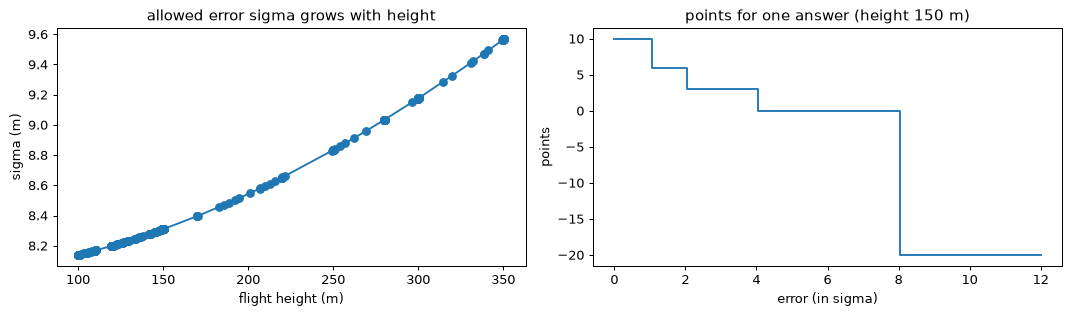

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(np.sort(heights), [sigma_m(h, camera.fx) for h in np.sort(heights)], "o-")
axes[0].set_xlabel("flight height (m)")
axes[0].set_ylabel("sigma (m)")
axes[0].set_title("allowed error sigma grows with height")
height_shown = float(np.median(heights))
errors_sigma = np.linspace(0, 12, 241)
axes[1].plot(errors_sigma, [points_for_error(e * sigma_m(height_shown, camera.fx), height_shown, camera.fx) for e in errors_sigma], drawstyle="steps-post")
axes[1].set_xlabel("error (in sigma)")
axes[1].set_ylabel("points")
axes[1].set_title("points for one answer (height %.0f m)" % height_shown)
plt.tight_layout()
plt.show()

# Part 2 · Image Processing: from one thermal photo to cells that can be compared with the map

In [5]:
photo = PHOTO if PHOTO is not None else int(np.argsort(heights)[len(heights) // 2])
item = test_set.items[photo]
level = int(test_set.query_levels[photo])
truth_x, truth_y = test_set.truths[photo]
print("photo %d | height %.0f m | zoom level %d (%.2f m per pixel) | sigma %.1f m" % (photo, item["rel_height"], level, level_gsd(level), test_set.sigmas[photo]))

photo 100 | height 150 m | zoom level 4 (1.20 m per pixel) | sigma 8.3 m


## 2.1 The photo and its north-up canvas

`load_thermal_frame` + `normalise_frame`: the raw thermal values are stretched to 0..1. `render_query` then undoes the lens, the tilt and the heading and puts the photo on a 224 x 224 canvas on the map grid, north up (`valid` marks the pixels that really come from the photo). On the right: the canvas laid over the true map tile, which is the proof that the geometry is right.

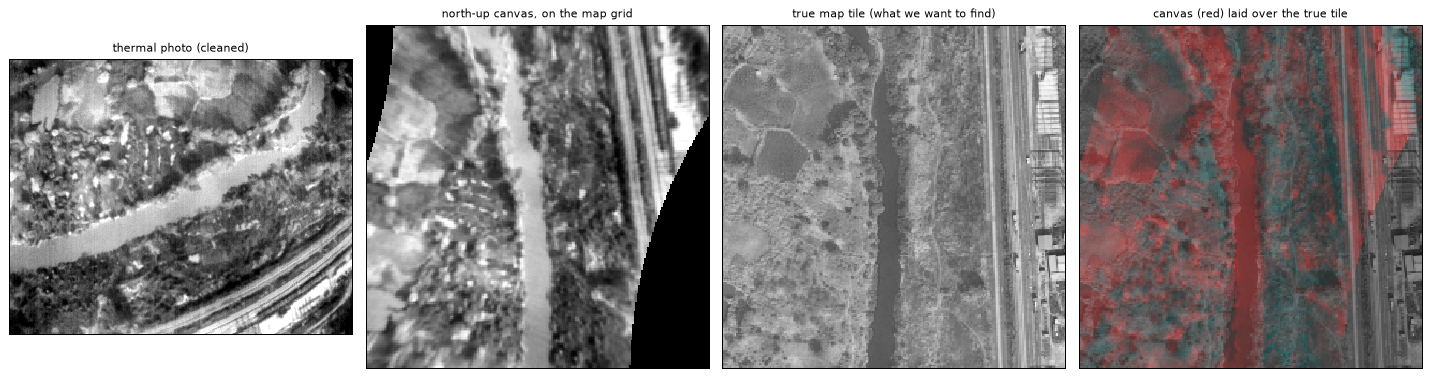

In [6]:
frame = normalise_frame(load_thermal_frame(item))
canvas, valid = render_query(item, camera, level)
true_tile = map_piece(level_images, level, truth_x, truth_y)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
show(axes[0], frame, "thermal photo (cleaned)")
show(axes[1], canvas * valid, "north-up canvas, on the map grid")
show(axes[2], true_tile, "true map tile (what we want to find)")
blend = np.stack([true_tile, true_tile, true_tile], axis=-1) * 0.6
blend[..., 0] = np.where(valid, 0.5 * blend[..., 0] + 0.5 * canvas, blend[..., 0])
show(axes[3], np.clip(blend, 0, 1), "canvas (red) laid over the true tile")
plt.tight_layout()
plt.show()

## 2.2 Edge cells: what the coarse search really compares

Brightness of a thermal photo and of a satellite picture do not agree, but **where edges run** does. The picture is cut into 4 x 4 pixel cells; each cell gets 8 numbers (how much edge in each direction). Colour = the dominant direction, brightness = edge strength.

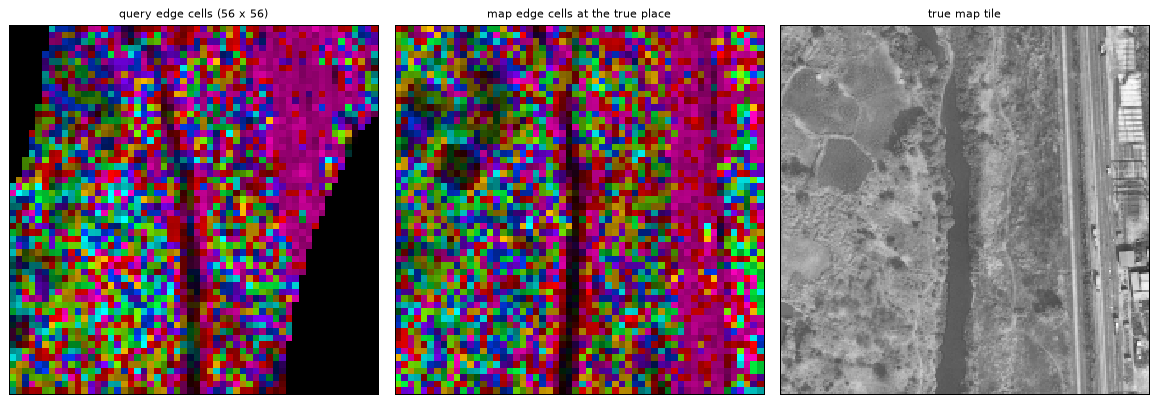

families: ['edge', 'mind', 'learned']


In [7]:
def cells_as_colour(cells):
    strength = cells.sum(axis=0)
    direction = np.argmax(cells, axis=0) / cells.shape[0]
    hsv = np.stack([direction, np.ones_like(strength), np.clip(strength / (np.percentile(strength, 99) + 1e-6), 0, 1)], axis=-1)
    return hsv_to_rgb(hsv)


families = {"edge": EdgeFamily(store), "mind": MindFamily(store, settings.LEVELS)}
f4_file = config.OUT_DIR / "models" / "f4.pt"
if f4_file.exists():
    families["learned"] = LearnedFamily(store, settings.LEVELS, f4_file)

query_cells, query_cell_valid = families["edge"].query(canvas, valid)
gsd = level_gsd(level)
top = int(round(truth_y / gsd / settings.CELL - 28))
left = int(round(truth_x / gsd / settings.CELL - 28))
true_cells = cut_map_features(families["edge"].map_features(level), top, left, 56, 56)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
show(axes[0], cells_as_colour(query_cells) * query_cell_valid[..., None], "query edge cells (56 x 56)")
show(axes[1], cells_as_colour(np.asarray(true_cells)), "map edge cells at the true place")
show(axes[2], true_tile, "true map tile")
plt.tight_layout()
plt.show()
print("families:", list(families))

# Part 3 · Coarse Search: where in the 5 km circle could this photo be?

`make_inputs` computes every score map of the photo once (FFT correlation of the query cells over the whole 5 km disc), `build_methods` holds the coarse methods (a method is a function that turns those maps into **one score map**), and `pick_peaks` keeps the 25 best distinct places. The COARSE setting picks the method; any other method is one small block in `train/coarse_methods/`.

In [8]:
names = ["edge_zncc", "edge_cosine", "edge_mag", "edge_zncc_w", "mind_zncc"]
if "learned" in families:
    names.append("learned_zncc")

fused_models = {}
state_file = config.OUT_DIR / "state.json"
if state_file.exists():
    best = json.load(open(state_file))["results"]["fusion_best"]
    model = load_model(config.OUT_DIR / "models" / "fusion" / (best["tag"] + ".pt")).to(device).eval()
    fused_models["fused"] = (model, best["subset"])
methods = build_methods(["edge_zncc"], fused_models=fused_models)
if COARSE not in methods:
    print("method %s is not available (no saved fusion model?) -> using edge_zncc" % COARSE)
    COARSE = "edge_zncc"
coarse_method = methods[COARSE]
print("coarse method:", COARSE, "| maps:", names)


def errors_in_sigma(peaks, photo_index):
    truth = test_set.truths[photo_index]
    errors = []
    for row in peaks:
        if row[1] < 1e8:
            errors.append(math.hypot(row[1] - truth[0], row[2] - truth[1]) / test_set.sigmas[photo_index])
        else:
            errors.append(1e9)
    return np.array(errors)


inputs = make_inputs(canvas, valid, level, test_set.priors[photo], families, names)
score_map = coarse_method(inputs)
peaks = pick_peaks(score_map, inputs["geometry"])
print("score map", tuple(score_map.shape), "-> peaks", peaks.shape, "(score, x, y, sharpness, ranking value)")

coarse method: fused | maps: ['edge_zncc', 'edge_cosine', 'edge_mag', 'edge_zncc_w', 'mind_zncc', 'learned_zncc']
score map (2085, 2085) -> peaks (25, 5) (score, x, y, sharpness, ranking value)


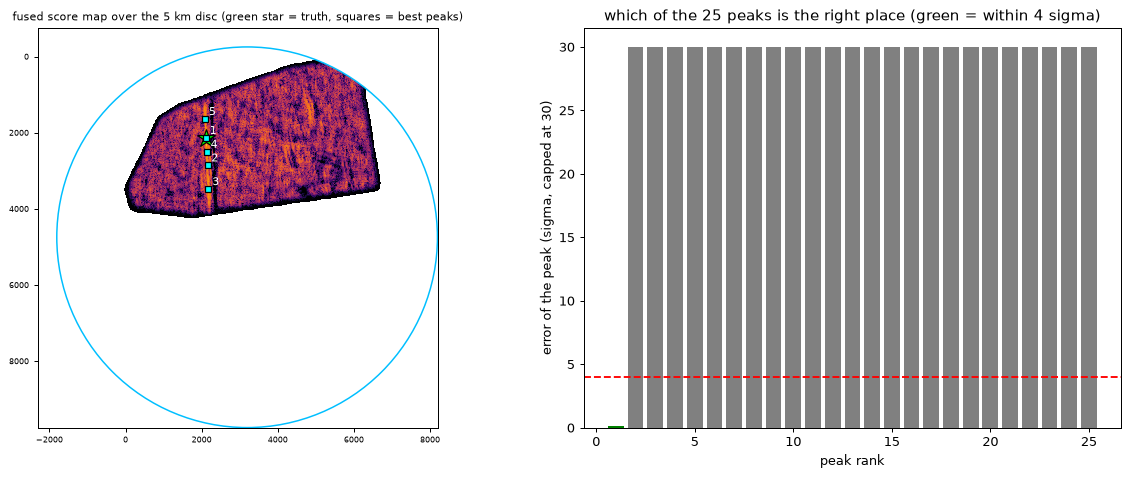

first peak error 0.1 sigma | best of the 25: 0.1 sigma


In [9]:
def draw_heat_map(axis, score_map, geometry, peaks, title, how_many=5):
    heat = score_map.cpu().numpy().copy()
    inside = geometry["inside"].cpu().numpy()
    heat[~inside | (heat <= -1)] = np.nan
    x_m = geometry["x_m"].cpu().numpy()
    y_m = geometry["y_m"].cpu().numpy()
    axis.imshow(heat, cmap="inferno", vmin=np.nanpercentile(heat, 5), vmax=np.nanmax(heat), extent=(x_m[0], x_m[-1], y_m[-1], y_m[0]))
    axis.add_patch(plt.Circle(test_set.priors[photo], settings.DISC_RADIUS, fill=False, color="deepskyblue", lw=1.2))
    axis.plot(truth_x, truth_y, "*", color="lime", markersize=15, markeredgecolor="black")
    for rank in range(how_many):
        if peaks[rank, 1] < 1e8:
            axis.plot(peaks[rank, 1], peaks[rank, 2], "s", color="cyan", markersize=5, markeredgecolor="black")
            axis.annotate(str(rank + 1), (peaks[rank, 1], peaks[rank, 2]), color="white", fontsize=9, xytext=(3, 3), textcoords="offset points")
    axis.set_title(title, fontsize=9)
    axis.tick_params(labelsize=6)


coarse_errors = errors_in_sigma(peaks, photo)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
draw_heat_map(axes[0], score_map, inputs["geometry"], peaks, "%s score map over the 5 km disc (green star = truth, squares = best peaks)" % COARSE)
axes[1].bar(range(1, 26), np.minimum(coarse_errors, 30), color=["green" if e <= 4 else "gray" for e in coarse_errors])
axes[1].axhline(4, color="red", ls="--")
axes[1].set_xlabel("peak rank")
axes[1].set_ylabel("error of the peak (sigma, capped at 30)")
axes[1].set_title("which of the 25 peaks is the right place (green = within 4 sigma)")
plt.tight_layout()
plt.show()
print("first peak error %.1f sigma | best of the 25: %.1f sigma" % (coarse_errors[0], coarse_errors.min()))

# Part 3b · Semantic layer: DINO looks again at the best 50 places

The coarse score only knows edge layout. DINO knows *what is there* (roofs, roads, fields). The layer takes the best **50** places of the coarse score map, cuts a map window exactly at each one, lets DINO compare it with the photo, re-orders the 50 and gives the best 25 to the fine stage. Switch: `USE_SEMANTIC_LAYER`.

Output has the same shape as `pick_peaks`, so nothing after it changes.

semantic layer: 0.3 s for 50 places


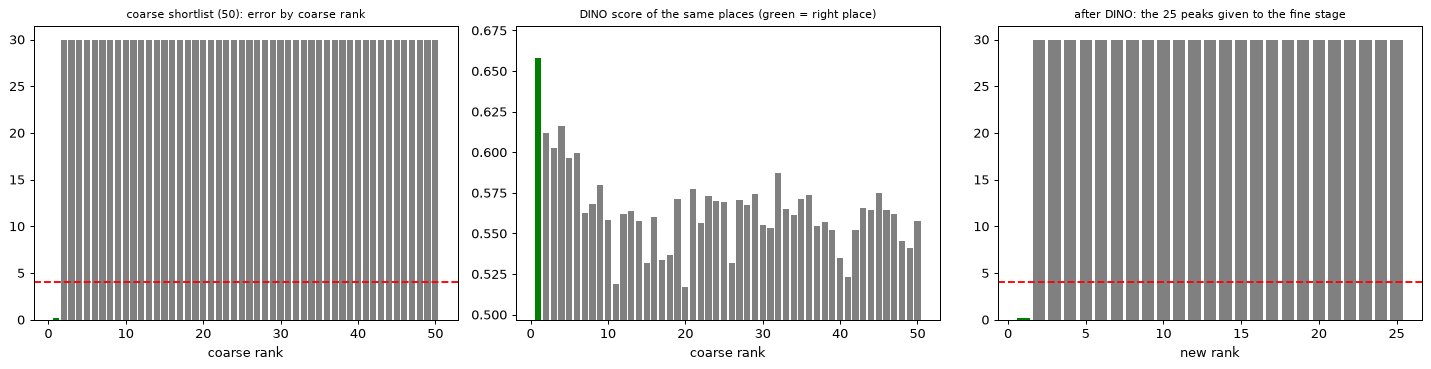

first peak error: 0.1 sigma (coarse) -> 0.1 sigma (after the semantic layer)


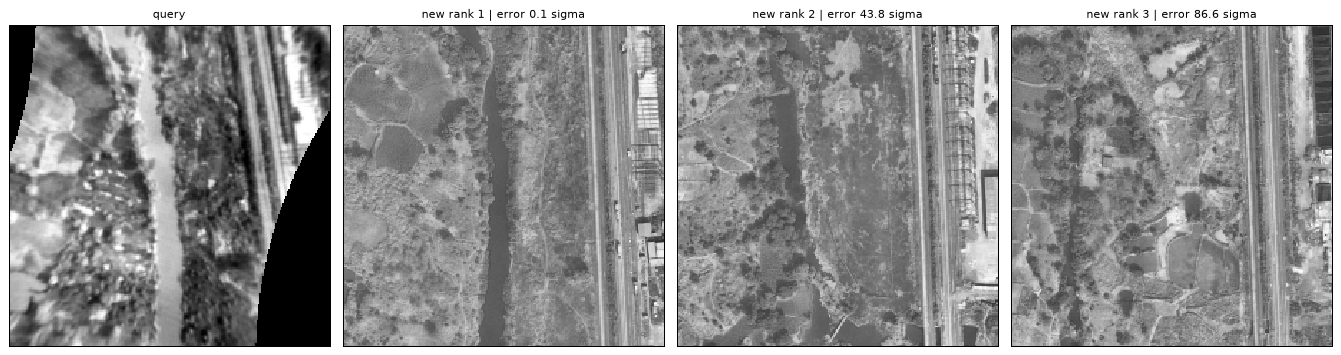

In [10]:
if USE_SEMANTIC_LAYER:
    encoder = load_encoder()
    start = time.time()
    semantic_peaks, details = semantic_layer(encoder, score_map, inputs["geometry"], canvas, valid, level, level_images)
    print("semantic layer: %.1f s for 50 places" % (time.time() - start))
    short_errors = errors_in_sigma(details["shortlist"], photo)
    after_errors = errors_in_sigma(semantic_peaks, photo)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    right = ["green" if e <= 4 else "gray" for e in short_errors]
    axes[0].bar(range(1, 51), np.minimum(short_errors, 30), color=right)
    axes[0].axhline(4, color="red", ls="--")
    axes[0].set_title("coarse shortlist (50): error by coarse rank", fontsize=9)
    axes[0].set_xlabel("coarse rank")
    axes[1].bar(range(1, 51), details["dense"], color=right)
    axes[1].set_ylim(np.nanmin(details["dense"]) - 0.02, np.nanmax(details["dense"]) + 0.02)
    axes[1].set_title("DINO score of the same places (green = right place)", fontsize=9)
    axes[1].set_xlabel("coarse rank")
    axes[2].bar(range(1, 26), np.minimum(after_errors, 30), color=["green" if e <= 4 else "gray" for e in after_errors])
    axes[2].axhline(4, color="red", ls="--")
    axes[2].set_title("after DINO: the 25 peaks given to the fine stage", fontsize=9)
    axes[2].set_xlabel("new rank")
    plt.tight_layout()
    plt.show()
    print("first peak error: %.1f sigma (coarse) -> %.1f sigma (after the semantic layer)" % (coarse_errors[0], after_errors[0]))

    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    show(axes[0], canvas * valid, "query")
    for slot in range(3):
        row = semantic_peaks[slot]
        show(axes[slot + 1], map_piece(level_images, level, row[1], row[2]), "new rank %d | error %.1f sigma" % (slot + 1, after_errors[slot]))
    plt.tight_layout()
    plt.show()
    final_peaks = semantic_peaks
else:
    print("semantic layer is off: the fine stage gets the coarse peaks")
    final_peaks = peaks

# Part 4 · Fine Matching: does the photo really match each candidate place?

For each of the 25 peaks, SuperPoint finds keypoints, LightGlue (MINIMA weights) matches them between the canvas and a map window around the peak, and RANSAC counts the **inliers** (matches that agree on one similarity transform) and the small position correction. More inliers = more sure.

In [11]:
nudt_dir = config.find_nudt_dir()
settings.MINIMA_FILE = nudt_dir / "checkpoint" / "MINIMA" / "minima_lightglue.pth"
matcher = load_matcher()

MINIMA weights loaded. File layers not in model: 0 | model layers not in file: 1
  missing (should be none or only harmless buffers): ['confidence_thresholds']


fine stage on 25 candidates: 0.7 s


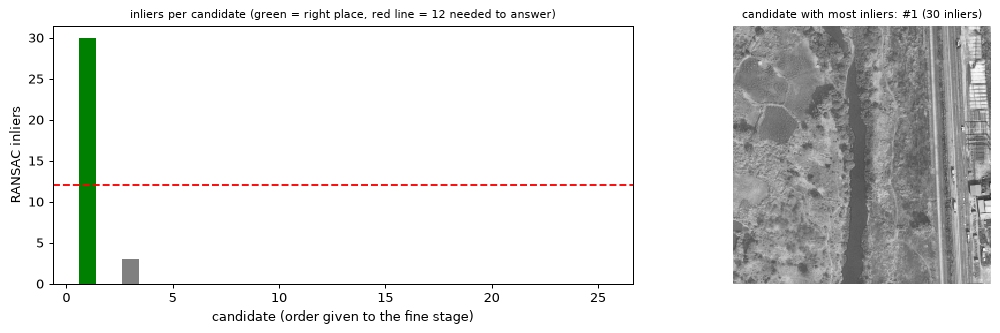

In [12]:
start = time.time()
stage2 = second_stage(matcher, canvas, valid, level, final_peaks, level_images)
print("fine stage on 25 candidates: %.1f s" % (time.time() - start))

final_errors = errors_in_sigma(final_peaks, photo)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(range(1, 26), stage2["inliers"], color=["green" if e <= 4 else "gray" for e in final_errors])
axes[0].axhline(12, color="red", ls="--")
axes[0].set_xlabel("candidate (order given to the fine stage)")
axes[0].set_ylabel("RANSAC inliers")
axes[0].set_title("inliers per candidate (green = right place, red line = 12 needed to answer)", fontsize=9)
best_candidate = int(np.argmax(stage2["inliers"]))
axes[1].axis("off")
show(axes[1], map_piece(level_images, level, final_peaks[best_candidate, 1], final_peaks[best_candidate, 2]),
     "candidate with most inliers: #%d (%d inliers)" % (best_candidate + 1, stage2["inliers"][best_candidate]))
plt.tight_layout()
plt.show()

# Part 5 · Result Thresholding: pick one place, or skip

`final_answer` takes the candidate with the most inliers and adds its small correction; with fewer than 12 inliers it falls back to the first peak and `decide` says to skip. A wrong answer costs 20 points and a right one gives at most 10, so unsure photos are skipped (0 points).

With the semantic layer on (`USE_SEMANTIC_DECISION`), `semantic_rerank.decision` is used instead: the candidate with the highest `inliers + GAMMA * (DINO z-score)` is chosen, and a photo with a few inliers too few can still be answered when DINO is very sure (`RESCUE_INLIERS`, `RESCUE_Z`). Reason: `second_stage` checks all 25 candidates on their own, so the order from the semantic layer alone cannot change the answer; the DINO score has to take part in the choice. With `GAMMA = 0` and no rescue the two give the same answers.


DINO z-score of the chosen place: 3.73
answer: chosen candidate #1, 30 inliers -> ANSWER
error 2.9 m = 0.35 sigma | points if answered: 10 | points we get: 10


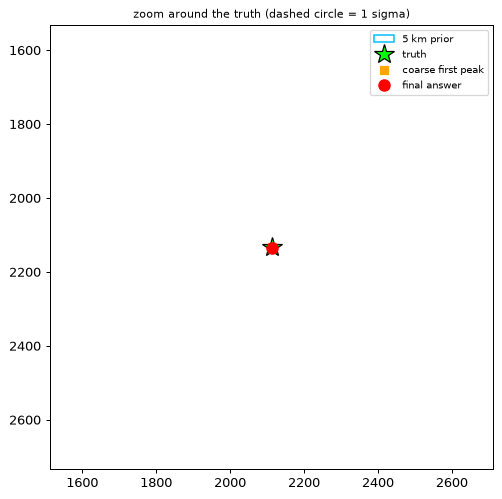

In [13]:
if USE_SEMANTIC_LAYER and USE_SEMANTIC_DECISION:
    z_candidates = candidate_z(final_peaks, details)
    x, y, inliers, chosen, z_chosen = choose_candidate(final_peaks, stage2, z_candidates, GAMMA)
    answered = decide_with_dino(inliers, z_chosen, RESCUE_INLIERS, RESCUE_Z)
    print("DINO z-score of the chosen place: %.2f" % z_chosen)
else:
    x, y, inliers, chosen = final_answer(final_peaks, stage2)
    answered = decide(inliers)
error_m = math.hypot(x - truth_x, y - truth_y)
points = points_for_error(error_m, item["rel_height"], camera.fx)
print("answer: chosen candidate #%d, %d inliers -> %s" % (chosen + 1, inliers, "ANSWER" if answered else "SKIP (0 points)"))
print("error %.1f m = %.2f sigma | points if answered: %d | points we get: %d" % (error_m, error_m / test_set.sigmas[photo], points, points if answered else 0))

fig, axis = plt.subplots(figsize=(6.4, 6.4))
axis.add_patch(plt.Circle(test_set.priors[photo], settings.DISC_RADIUS, fill=False, color="deepskyblue", lw=1.2, label="5 km prior"))
axis.plot(*test_set.priors[photo], "x", color="deepskyblue", markersize=8)
axis.plot(truth_x, truth_y, "*", color="lime", markersize=16, markeredgecolor="black", label="truth")
axis.plot(peaks[0, 1], peaks[0, 2], "s", color="orange", label="coarse first peak")
axis.plot(x, y, "o", color="red", markersize=9, label="final answer")
axis.set_aspect("equal")
axis.set_xlim(truth_x - 600, truth_x + 600)
axis.set_ylim(truth_y + 600, truth_y - 600)
axis.add_patch(plt.Circle((truth_x, truth_y), test_set.sigmas[photo], fill=False, color="lime", ls="--"))
axis.legend(fontsize=8)
axis.set_title("zoom around the truth (dashed circle = 1 sigma)", fontsize=9)
plt.show()

# Part 6 · Evaluation: the whole chain on many photos

Each photo is handled alone (as in flight). The coarse stage is run once; the fine stage runs twice, on the 25 coarse peaks and on the 25 peaks after the semantic layer. Three answers are scored with the contest points (skipped photos count 0), all on the same photos and priors:

1. **coarse only**: the 25 coarse peaks, answer by inliers.
2. **with semantic layer**: the 25 peaks after DINO, answer by inliers (what the layer alone can do; the order of the peaks does not matter to the fine stage, so only the choice of the 25 changes).
3. **layer + DINO decision**: the same fine-stage result as 2, but the answer is chosen and gated with the DINO score (`GAMMA`, `RESCUE_*`).

Variant 3 needs no extra fine-stage run. The inliers, shifts and DINO scores of every candidate are kept in `stored`, so the decision rule can be changed and re-scored in Part 6b without matching again. `N_EVAL` photos; the fine stage dominates the time.


In [14]:
records = []
stored = []
start = time.time()
encoder_now = encoder if USE_SEMANTIC_LAYER else load_encoder()
for index in range(min(N_EVAL, len(test_set.items))):
    try:
        item_now = test_set.items[index]
        level_now = int(test_set.query_levels[index])
        canvas_now, valid_now = render_query(item_now, camera, level_now)
        inputs_now = make_inputs(canvas_now, valid_now, level_now, test_set.priors[index], families, names)
        score_now = coarse_method(inputs_now)
        plain_peaks = pick_peaks(score_now, inputs_now["geometry"])
        layered_peaks, details_now = semantic_layer(encoder_now, score_now, inputs_now["geometry"], canvas_now, valid_now, level_now, level_images)
        z_now = candidate_z(layered_peaks, details_now)
        truth_now = test_set.truths[index]
        row = dict(photo=index, height=item_now["rel_height"], sigma=test_set.sigmas[index])

        plain_stage = second_stage(matcher, canvas_now, valid_now, level_now, plain_peaks, level_images)
        ax, ay, n_inliers, _ = final_answer(plain_peaks, plain_stage)
        error_now = math.hypot(ax - truth_now[0], ay - truth_now[1])
        earned = points_for_error(error_now, item_now["rel_height"], camera.fx)
        row["coarse only peak1 sigma"] = errors_in_sigma(plain_peaks, index)[0]
        row["coarse only sigma"] = error_now / test_set.sigmas[index]
        row["coarse only points"] = earned if decide(n_inliers) else 0

        layer_stage = second_stage(matcher, canvas_now, valid_now, level_now, layered_peaks, level_images)
        ax, ay, n_inliers, _ = final_answer(layered_peaks, layer_stage)
        error_now = math.hypot(ax - truth_now[0], ay - truth_now[1])
        earned = points_for_error(error_now, item_now["rel_height"], camera.fx)
        row["with semantic layer peak1 sigma"] = errors_in_sigma(layered_peaks, index)[0]
        row["with semantic layer sigma"] = error_now / test_set.sigmas[index]
        row["with semantic layer points"] = earned if decide(n_inliers) else 0

        ax, ay, n_inliers, _, z_best = choose_candidate(layered_peaks, layer_stage, z_now, GAMMA)
        error_now = math.hypot(ax - truth_now[0], ay - truth_now[1])
        earned = points_for_error(error_now, item_now["rel_height"], camera.fx)
        row["layer + DINO decision peak1 sigma"] = row["with semantic layer peak1 sigma"]
        row["layer + DINO decision sigma"] = error_now / test_set.sigmas[index]
        if decide_with_dino(n_inliers, z_best, RESCUE_INLIERS, RESCUE_Z):
            row["layer + DINO decision points"] = earned
        else:
            row["layer + DINO decision points"] = 0
        records.append(row)
        stored.append(dict(photo=index, height=item_now["rel_height"], peaks=layered_peaks.copy(), stage2=layer_stage, z=z_now, truth=truth_now))
    except Exception as error:
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:100]))
    if device == "cuda":
        torch.cuda.empty_cache()
    if index % 10 == 0:
        print("photo %d, %.0f s" % (index + 1, time.time() - start))
results = pd.DataFrame(records)
print(len(results), "photos done in %.0f s" % (time.time() - start))


photo 1, 3 s
photo 11, 23 s
photo 21, 40 s
photo 31, 57 s
photo 41, 79 s
photo 51, 98 s
photo 61, 117 s
photo 71, 136 s
photo 81, 154 s
photo 91, 173 s
photo 101, 192 s
photo 111, 214 s
photo 121, 235 s
photo 131, 254 s
photo 141, 272 s
photo 151, 293 s
photo 161, 314 s
photo 171, 334 s
photo 181, 354 s
photo 191, 374 s
200 photos done in 391 s


,first peak <= 4 sigma,final answer <= 1 sigma,final answer <= 4 sigma,answered,score (/60)
variant,,,,,
coarse only,0.905,0.690,0.930,0.78,41.49
with semantic layer,0.960,0.705,0.960,0.78,41.49
layer + DINO decision,0.960,0.680,0.925,0.78,41.49


points per photo, with semantic layer minus coarse only: +0.000  (95% interval +0.000 to +0.000, 0 photos better, 0 worse)
points per photo, layer + DINO decision minus coarse only: +0.000  (95% interval +0.000 to +0.000, 0 photos better, 0 worse)
points per photo, layer + DINO decision minus with semantic layer: +0.000  (95% interval +0.000 to +0.000, 0 photos better, 0 worse)


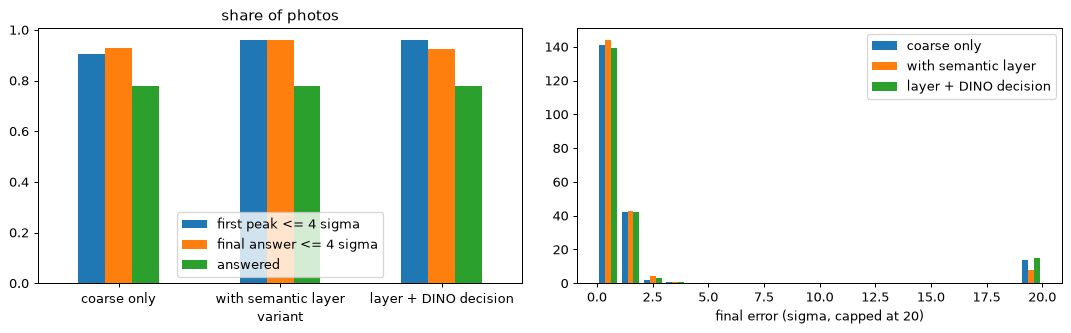

In [15]:
VARIANTS = ("coarse only", "with semantic layer", "layer + DINO decision")
rows = []
for variant in VARIANTS:
    rows.append({"variant": variant,
                 "first peak <= 4 sigma": (results[variant + " peak1 sigma"] <= 4).mean(),
                 "final answer <= 1 sigma": (results[variant + " sigma"] <= 1).mean(),
                 "final answer <= 4 sigma": (results[variant + " sigma"] <= 4).mean(),
                 "answered": (results[variant + " points"] != 0).mean(),
                 "score (/60)": final_score(list(results[variant + " points"]))})
summary = pd.DataFrame(rows).set_index("variant")
display(summary.round(3))


def paired_difference(better, worse, seed=0):
    generator = np.random.default_rng(seed)
    difference = (results[better + " points"] - results[worse + " points"]).values
    means = []
    for _ in range(5000):
        picks = generator.integers(0, len(difference), len(difference))
        means.append(difference[picks].mean())
    print("points per photo, %s minus %s: %+.3f  (95%% interval %+.3f to %+.3f, %d photos better, %d worse)" % (
        better, worse, difference.mean(), np.quantile(means, 0.025), np.quantile(means, 0.975), (difference > 0).sum(), (difference < 0).sum()))


paired_difference("with semantic layer", "coarse only")
paired_difference("layer + DINO decision", "coarse only")
paired_difference("layer + DINO decision", "with semantic layer")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
summary[["first peak <= 4 sigma", "final answer <= 4 sigma", "answered"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("share of photos")
axes[1].hist([results[v + " sigma"].clip(upper=20) for v in VARIANTS], bins=20, label=list(VARIANTS))
axes[1].set_xlabel("final error (sigma, capped at 20)")
axes[1].legend()
plt.tight_layout()
plt.show()


## Part 6b · Which decision rule? (no new matching needed)

`stored` keeps, for every photo, the 25 peaks, the inliers and shifts, and the DINO z-score of each candidate. Any rule can be scored again from it in seconds. The grid below tries `GAMMA` (weight of DINO when choosing) and rescue rules (answer with fewer than 12 inliers when DINO is sure).

**Read it carefully.** The grid is searched on the same photos it is scored on, so the best row is optimistic. The two halves (photos 0 to N/2 and N/2 to N) are scored separately: a rule is only believable if it helps in **both** halves. Photos with a wrong answer cost 20 points, so a rescue rule that answers more can also lose points.


In [16]:
def score_rule(entries, gamma, rescue):
    points = []
    for entry in entries:
        ax, ay, n_inliers, _, z_best = choose_candidate(entry["peaks"], entry["stage2"], entry["z"], gamma)
        error_m = math.hypot(ax - entry["truth"][0], ay - entry["truth"][1])
        earned = points_for_error(error_m, entry["height"], camera.fx)
        if rescue is None:
            answered = decide_with_dino(n_inliers, z_best)
        else:
            answered = decide_with_dino(n_inliers, z_best, rescue[0], rescue[1])
        if answered:
            points.append(earned)
        else:
            points.append(0)
    return points


half = len(stored) // 2
rules = []
for gamma in (0.0, 0.5, 1.0, 2.0, 4.0):
    for rescue in (None, (10, 1.5), (9, 2.0), (8, 2.0), (8, 3.0)):
        rules.append((gamma, rescue))

table = []
for gamma, rescue in rules:
    everything = score_rule(stored, gamma, rescue)
    first_half = score_rule(stored[:half], gamma, rescue)
    second_half = score_rule(stored[half:], gamma, rescue)
    table.append({"gamma": gamma, "rescue (inliers, z)": str(rescue),
                  "score (/60)": final_score(everything),
                  "answered": sum(1 for p in everything if p != 0) / len(everything),
                  "first half": final_score(first_half), "second half": final_score(second_half)})
sweep = pd.DataFrame(table)
display(sweep.sort_values("score (/60)", ascending=False).round(2).reset_index(drop=True))
print("gamma = 0 and no rescue is the reference (inliers only, on the layer's 25 peaks)")


,gamma,"rescue (inliers, z)",score (/60),answered,first half,second half
0,0.0,"(9, 2.0)",41.79,0.78,38.88,44.7
1,0.5,"(9, 2.0)",41.79,0.78,38.88,44.7
2,0.0,"(8, 2.0)",41.79,0.78,38.88,44.7
3,0.5,"(8, 2.0)",41.79,0.78,38.88,44.7
4,4.0,"(9, 2.0)",41.79,0.78,38.88,44.7
5,2.0,"(9, 2.0)",41.79,0.78,38.88,44.7
6,2.0,"(8, 2.0)",41.79,0.78,38.88,44.7
7,1.0,"(8, 2.0)",41.79,0.78,38.88,44.7
8,1.0,"(9, 2.0)",41.79,0.78,38.88,44.7
9,4.0,"(8, 2.0)",41.79,0.78,38.88,44.7


gamma = 0 and no rescue is the reference (inliers only, on the layer's 25 peaks)


**Caveats.** Photos and map are from the development set; the real evaluation uses a different map. A small `N_EVAL` has wide intervals: read the interval, not only the mean. The learned fusion was trained on the NUDT (Changsha) data, so the official photos test it on another city.